
# Hackflash: Healthcare Cost Intelligence

## Problem Statement 2

Healthcare Cost Intelligence aims to understand the factors contributing to healthcare expenditure. This project investigates whether high total billing is primarily associated with a high volume of patients or a high average bill per patient.


In [1]:

# Import libraries for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure the appearance of plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Display more columns when inspecting dataframes
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

# Upload the healthcare CSV file into Google Colab

from google.colab import files

uploaded = files.upload()


Saving healthcare_dataset.csv to healthcare_dataset.csv


In [3]:

# Load the uploaded dataset into a pandas DataFrame

file_name = "healthcare_dataset.csv"

df = pd.read_csv(file_name)

# Display the first five records
display(df.head())


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,31/01/2024,Matthew Smith,Sons and Miller,Blue Cross,18856.28131,328,Urgent,02/02/2024,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,20/08/2019,Samantha Davies,Kim Inc,Medicare,33643.32729,265,Emergency,26/08/2019,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,22/09/2022,Tiffany Mitchell,Cook PLC,Aetna,27955.09608,205,Emergency,07/10/2022,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,18/11/2020,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.78241,450,Elective,18/12/2020,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,19/09/2022,Kathleen Hanna,White-White,Aetna,14238.31781,458,Urgent,09/10/2022,Penicillin,Abnormal


In [4]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Inspect column names
print("\nColumn names:")
print(df.columns.tolist())

# Inspect data types and non-null counts
print("\nDataset information:")
df.info()

# Generate summary statistics for numerical columns
print("\nNumerical summary:")
display(df.describe())


Dataset shape: (55500, 15)

Column names:
['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition', 'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider', 'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date', 'Medication', 'Test Results']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amount      55498 non-null  float64
 10  Room Numb

,Age,Billing Amount,Room Number
count,55500.000000,55498.000000,55500.000000
mean,51.539459,25539.370370,301.134829
std,19.602454,14211.399770,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.824345,202.000000
50%,52.000000,25538.069380,302.000000
75%,68.000000,37819.858157,401.000000
max,89.000000,52764.276740,500.000000


In [5]:

# Count missing values and calculate their percentage per column

missing_audit = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_audit.sort_values(
        by="Missing Count",
        ascending=False
    )
)


,Missing Count,Missing Percentage
Billing Amount,2,0.0
Age,0,0.0
Name,0,0.0
Blood Type,0,0.0
Medical Condition,0,0.0
Date of Admission,0,0.0
Gender,0,0.0
Doctor,0,0.0
Hospital,0,0.0
Insurance Provider,0,0.0


In [6]:

# Count fully duplicated rows

duplicate_count = df.duplicated().sum()

print("Fully duplicated rows:", duplicate_count)

# Inspect the duplicate records, if any
display(df[df.duplicated(keep=False)].head(10))


Fully duplicated rows: 534


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
64,Nancy glOVeR,58,Male,A-,Hypertension,08/05/2020,Jennifer Larson,"Khan, and Rodriguez Fischer",Medicare,19183.168890,378,Emergency,01/06/2020,Aspirin,Abnormal
107,DAVid higgInS,49,Female,B-,Arthritis,05/03/2021,Erin Henderson MD,"Evans and Hall Schneider,",Medicare,24948.477820,361,Emergency,20/03/2021,Penicillin,Abnormal
148,RoBErt hIGGInS,42,Male,AB-,Asthma,06/05/2021,Scott Davis,"and Ford Lee, Rodriguez",Medicare,13355.782090,451,Elective,29/05/2021,Ibuprofen,Inconclusive
154,kevIn HiCKs,66,Male,AB+,Arthritis,23/06/2021,Kelly Murphy,Robinson Inc,Medicare,1897.891727,196,Elective,09/07/2021,Ibuprofen,Abnormal
159,miCHAeL TayloR,29,Male,O-,Asthma,27/02/2020,Erica Mccormick,Donaldson-Frey,Medicare,41939.119940,453,Elective,26/03/2020,Ibuprofen,Normal
246,wiLlIAm mcCOY,80,Male,A-,Asthma,20/02/2023,Whitney Vaughan,"and Walker Glenn, Long",Cigna,3845.397496,158,Emergency,10/03/2023,Penicillin,Normal
360,tHOMas DENnIs,40,Male,A+,Asthma,28/01/2024,Leonard Chen,Mckinney-Edwards,Medicare,42959.299810,410,Elective,21/02/2024,Paracetamol,Abnormal
408,MelIssA hOFfMAN,36,Male,B+,Cancer,27/07/2022,April Cummings,Cooley-Reid,Cigna,41311.293900,434,Emergency,19/08/2022,Lipitor,Inconclusive
454,jOrdan LEON,51,Female,O+,Arthritis,11/08/2023,Christina Lopez,Dennis-Roth,Cigna,21534.715570,198,Emergency,20/08/2023,Penicillin,Normal
621,JesSIcA caRtER,51,Female,A-,Obesity,08/12/2019,Sarah Ibarra,Anderson Group,Cigna,32006.031570,200,Urgent,05/01/2020,Penicillin,Normal


In [7]:

# Check basic validity of age and billing amount

print("Age summary:")
display(df["Age"].describe())

print("\nAge values outside the range 0-120:")
print(
    ((df["Age"] < 0) | (df["Age"] > 120)).sum()
)

print("\nNegative billing amounts:")
print((df["Billing Amount"] < 0).sum())

print("\nZero billing amounts:")
print((df["Billing Amount"] == 0).sum())


Age summary:


,Age
count,55500.000000
mean,51.539459
std,19.602454
min,13.000000
25%,35.000000
50%,52.000000
75%,68.000000
max,89.000000



Age values outside the range 0-120:
0

Negative billing amounts:
108

Zero billing amounts:
0


In [8]:

# Inspect unique values in categorical columns

categorical_columns = [
    "Gender",
    "Blood Type",
    "Medical Condition",
    "Insurance Provider",
    "Admission Type",
    "Medication",
    "Test Results"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(sorted(df[column].dropna().astype(str).unique()))



Gender:
['Female', 'Male']

Blood Type:
['A+', 'A-', 'AB+', 'AB-', 'B+', 'B-', 'O+', 'O-']

Medical Condition:
['Arthritis', 'Asthma', 'Cancer', 'Diabetes', 'Hypertension', 'Obesity']

Insurance Provider:
['Aetna', 'Blue Cross', 'Cigna', 'Medicare', 'UnitedHealthcare']

Admission Type:
['Elective', 'Emergency', 'Urgent']

Medication:
['Aspirin', 'Ibuprofen', 'Lipitor', 'Paracetamol', 'Penicillin']

Test Results:
['Abnormal', 'Inconclusive', 'Normal']


In [9]:

# Preserve the original data before making any changes
df_original = df.copy(deep=True)

# Store every cleaning action for transparent reporting
cleaning_log = []

def log_cleaning(action, rows_affected, reason):
    cleaning_log.append({
        "Action": action,
        "Rows Affected": int(rows_affected),
        "Reason": reason
    })

print("Original dataset preserved:", df_original.shape)


Original dataset preserved: (55500, 15)


In [10]:

# Audit inconsistent capitalization in text fields.
# We inspect first, rather than blindly changing names.

for column in ["Name", "Doctor", "Hospital"]:
    values = df_original[column].dropna().astype(str)

    mixed_case_count = (
        values.ne(values.str.title())
    ).sum()

    print(
        f"{column}: {mixed_case_count} values "
        "differ from title case"
    )


Name: 55467 values differ from title case
Doctor: 1246 values differ from title case
Hospital: 27859 values differ from title case


In [11]:

# Create the working dataset
df_clean = df_original.copy()

# Remove leading/trailing whitespace from text fields
text_columns = df_clean.select_dtypes(
    include=["object"]
).columns

for column in text_columns:
    before = df_clean[column].copy()
    df_clean[column] = df_clean[column].str.strip()

    changed = (
        before.notna() &
        df_clean[column].notna() &
        before.ne(df_clean[column])
    ).sum()

    if changed:
        log_cleaning(
            f"Trim whitespace in {column}",
            changed,
            "Remove accidental leading/trailing spaces."
        )

# Parse dates explicitly using day/month/year format
for column in ["Date of Admission", "Discharge Date"]:
    df_clean[column] = pd.to_datetime(
        df_clean[column],
        format="%d/%m/%Y",
        errors="coerce"
    )

print("Date parsing complete.")
print(df_clean[[
    "Date of Admission",
    "Discharge Date"
]].dtypes)

print("\nInvalid or unparsed dates:")
print(
    df_clean[[
        "Date of Admission",
        "Discharge Date"
    ]].isna().sum()
)


Date parsing complete.
Date of Admission    datetime64[ns]
Discharge Date       datetime64[ns]
dtype: object

Invalid or unparsed dates:
Date of Admission    0
Discharge Date       0
dtype: int64


In [12]:

# Remove fully duplicated records, keeping the first occurrence
duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

log_cleaning(
    "Remove exact duplicate rows",
    duplicates_before,
    "Keep one copy of each fully identical record."
)

print("Duplicate rows removed:", duplicates_before)
print("Shape after deduplication:", df_clean.shape)


Duplicate rows removed: 534
Shape after deduplication: (54966, 15)


In [13]:

# Identify billing records that cannot be used in the
# primary analysis of positive healthcare charges

missing_billing = df_clean["Billing Amount"].isna()
negative_billing = df_clean["Billing Amount"] < 0

print("Missing billing:", missing_billing.sum())
print("Negative billing:", negative_billing.sum())

# Preserve all cleaned records in df_clean.
# Create a separate dataset for positive-billing analysis.
df_cost = df_clean.loc[
    df_clean["Billing Amount"].notna() &
    (df_clean["Billing Amount"] >= 0)
].copy()

log_cleaning(
    "Exclude records with missing billing from cost analysis",
    missing_billing.sum(),
    "Billing amount is required for cost calculations."
)

log_cleaning(
    "Exclude records with negative billing from primary cost analysis",
    negative_billing.sum(),
    "Investigate negative charges separately before interpreting costs."
)

print("\nCleaned master dataset:", df_clean.shape)
print("Primary cost-analysis dataset:", df_cost.shape)


Missing billing: 2
Negative billing: 106

Cleaned master dataset: (54966, 15)
Primary cost-analysis dataset: (54858, 15)


In [14]:

# Calculate the difference between admission and discharge dates
df_clean["Length of Stay"] = (
    df_clean["Discharge Date"] -
    df_clean["Date of Admission"]
).dt.days

# Count invalid dates and negative lengths of stay
invalid_date_rows = (
    df_clean["Date of Admission"].isna() |
    df_clean["Discharge Date"].isna()
)

negative_stay = df_clean["Length of Stay"] < 0
zero_stay = df_clean["Length of Stay"] == 0

print("Records with unparsed dates:", invalid_date_rows.sum())
print("Negative lengths of stay:", negative_stay.sum())
print("Zero-day stays:", zero_stay.sum())

# Display examples of negative stays for investigation
display(
    df_clean.loc[
        negative_stay,
        [
            "Date of Admission",
            "Discharge Date",
            "Length of Stay"
        ]
    ].head(10)
)


Records with unparsed dates: 0
Negative lengths of stay: 0
Zero-day stays: 0


,Date of Admission,Discharge Date,Length of Stay


In [15]:
# Create Length of Stay in the cost-analysis dataset.
# This cell makes df_analysis reproducible after a fresh runtime restart.

df_cost["Length of Stay"] = (
    df_cost["Discharge Date"] -
    df_cost["Date of Admission"]
).dt.days

# Keep records with valid dates and a non-negative stay duration.
valid_stay = (
    df_cost["Date of Admission"].notna() &
    df_cost["Discharge Date"].notna() &
    (df_cost["Length of Stay"] >= 0)
)

excluded_stay_count = (~valid_stay).sum()
df_analysis = df_cost.loc[valid_stay].copy()

log_cleaning(
    "Exclude invalid dates or negative stays from stay analysis",
    excluded_stay_count,
    "A valid non-negative length of stay is required."
)

print("Cleaned master dataset:", df_clean.shape)
print("Cost-analysis dataset:", df_cost.shape)
print("Final analysis dataset:", df_analysis.shape)
display(df_analysis["Length of Stay"].describe())


Cleaned master dataset: (54966, 16)
Cost-analysis dataset: (54858, 16)
Final analysis dataset: (54858, 16)


,Length of Stay
count,54858.000000
mean,15.499016
std,8.661316
min,1.000000
25%,8.000000
50%,15.000000
75%,23.000000
max,30.000000


In [16]:

# Summary of healthcare billing and length of stay

summary = df_analysis[
    ["Billing Amount", "Length of Stay", "Age"]
].describe().round(2)

display(summary)

# Total and average billing
print("Total billing:", round(
    df_analysis["Billing Amount"].sum(), 2
))

print("Average billing per record:", round(
    df_analysis["Billing Amount"].mean(), 2
))

print("Median billing per record:", round(
    df_analysis["Billing Amount"].median(), 2
))

print("Average length of stay:", round(
    df_analysis["Length of Stay"].mean(), 2
), "days")


,Billing Amount,Length of Stay,Age
count,54858.00,54858.00,54858.00
mean,25594.69,15.50,51.53
std,14175.81,8.66,19.61
min,9.24,1.00,13.00
25%,13299.93,8.00,35.00
50%,25593.87,15.00,52.00
75%,37846.11,23.00,68.00
max,52764.28,30.00,89.00


Total billing: 1404073534.71
Average billing per record: 25594.69
Median billing per record: 25593.87
Average length of stay: 15.5 days


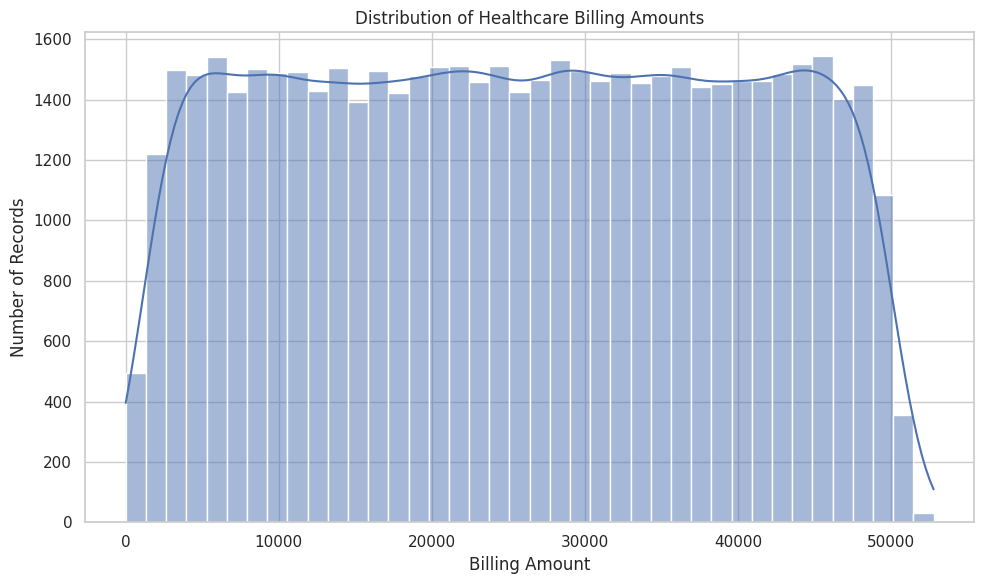

In [17]:

# Plot the distribution of billing amounts

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_analysis,
    x="Billing Amount",
    bins=40,
    kde=True
)

plt.title("Distribution of Healthcare Billing Amounts")
plt.xlabel("Billing Amount")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


In [18]:

# Aggregate hospital-level billing metrics

hospital_costs = (
    df_analysis.groupby("Hospital")
    .agg(
        Patient_Count=("Billing Amount", "size"),
        Total_Billing=("Billing Amount", "sum"),
        Average_Billing=("Billing Amount", "mean"),
        Median_Billing=("Billing Amount", "median")
    )
    .reset_index()
)

# Show hospitals with the highest total billing
top_total_billing = hospital_costs.nlargest(
    10, "Total_Billing"
)

display(top_total_billing.round(2))


,Hospital,Patient_Count,Total_Billing,Average_Billing,Median_Billing
14844,Johnson PLC,37,1081477.31,29229.12,30447.00
16849,LLC Smith,44,1030189.87,23413.41,18683.64
28861,Smith PLC,36,1029424.45,28595.12,29553.37
18556,Ltd Smith,39,1003365.53,25727.32,24722.11
28841,Smith Ltd,37,970035.87,26217.19,25046.64
14808,Johnson Inc,32,936931.27,29279.10,31095.43
10863,Group Smith,32,902975.79,28217.99,26185.00
13729,Inc Brown,27,877961.31,32517.09,35319.12
16632,LLC Johnson,30,816438.35,27214.61,24754.83
28803,Smith Group,34,806767.93,23728.47,23332.46


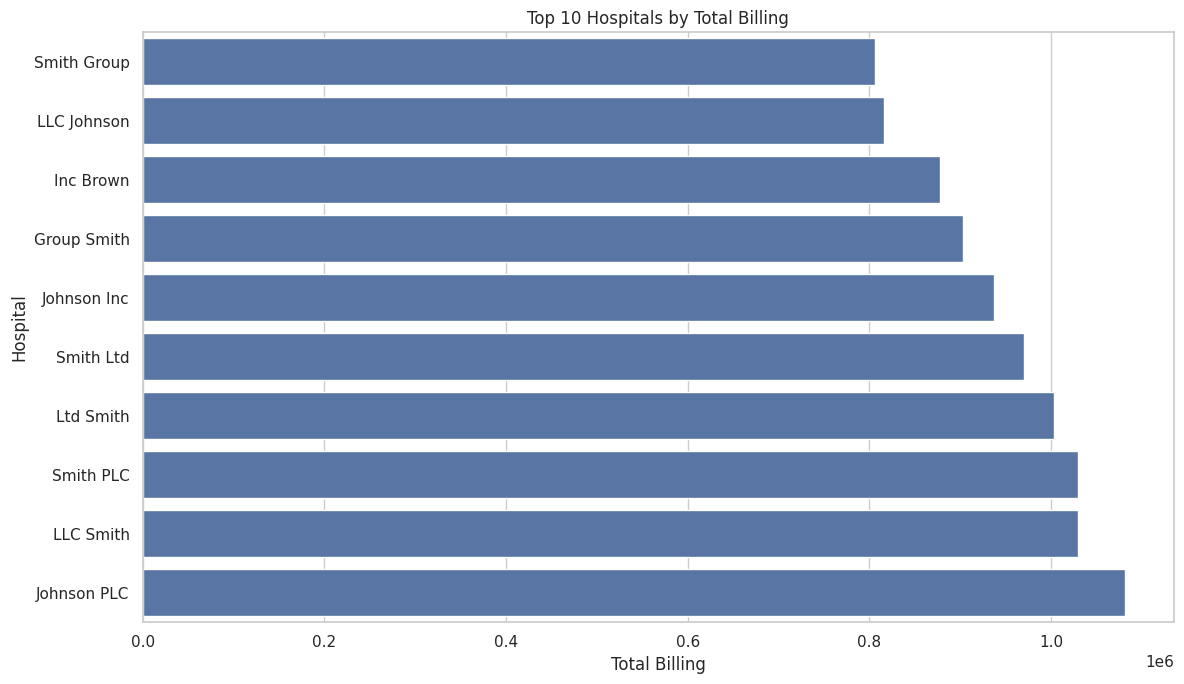

In [19]:

# Compare the 10 hospitals with the highest total billing

plot_data = top_total_billing.sort_values(
    "Total_Billing", ascending=True
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=plot_data,
    x="Total_Billing",
    y="Hospital"
)

plt.title("Top 10 Hospitals by Total Billing")
plt.xlabel("Total Billing")
plt.ylabel("Hospital")
plt.tight_layout()
plt.show()


,Hospital,Patient_Count,Total_Billing,Average_Billing,Median_Billing
12406,Hernandez-Morton,2,104746.06,52373.03,52373.03
32361,Walker-Garcia,2,104340.07,52170.04,52170.04
27299,Ruiz-Anthony,1,52154.24,52154.24,52154.24
9269,George-Gonzalez,1,52102.24,52102.24,52102.24
26616,Rocha-Carter,1,52092.67,52092.67,52092.67
2773,"Briggs Walker Martinez, and",1,52024.73,52024.73,52024.73
38680,"and Small Stephens Harrington,",2,103951.94,51975.97,51975.97
4885,Clark-Espinoza,1,51848.20,51848.20,51848.20
24837,"Pierce and Miller James,",1,51722.12,51722.12,51722.12
30272,Stephens Ltd,1,51714.30,51714.30,51714.30


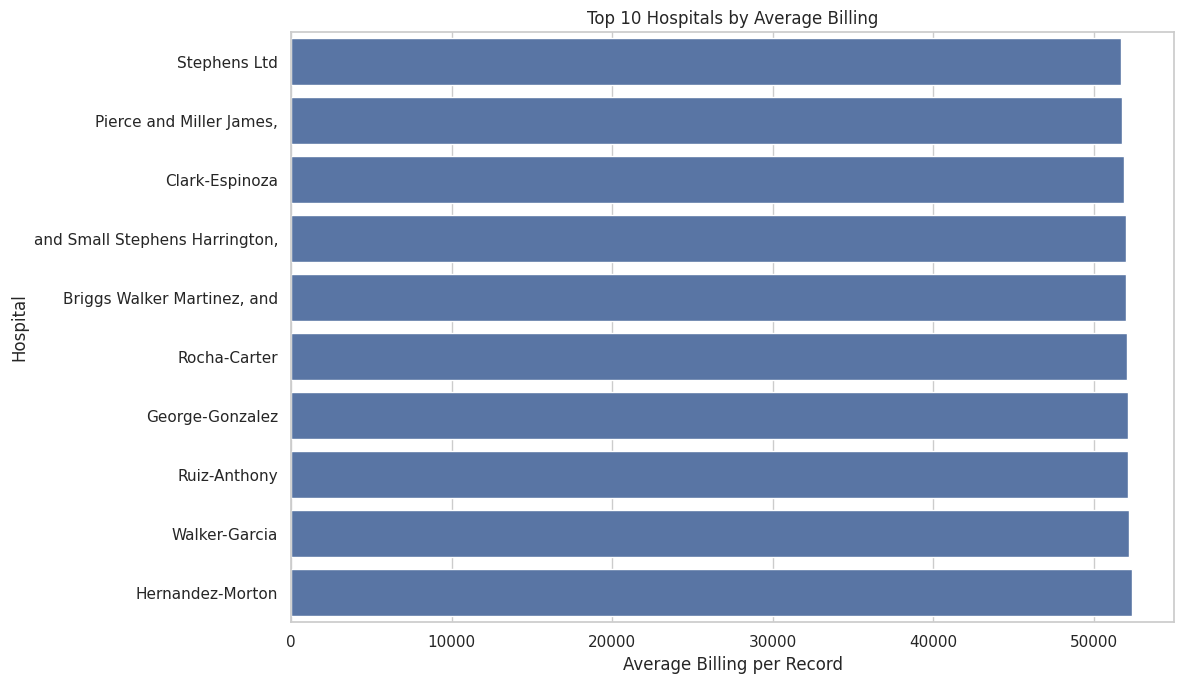

In [20]:

# Identify hospitals with the highest average billing per record

top_average_billing = hospital_costs.nlargest(
    10, "Average_Billing"
)

display(top_average_billing.round(2))

# Plot the results
plot_data = top_average_billing.sort_values(
    "Average_Billing", ascending=True
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=plot_data,
    x="Average_Billing",
    y="Hospital"
)

plt.title("Top 10 Hospitals by Average Billing")
plt.xlabel("Average Billing per Record")
plt.ylabel("Hospital")
plt.tight_layout()
plt.show()


In [21]:

# Summarize costs by insurance provider

insurance_costs = (
    df_analysis.groupby("Insurance Provider")
    .agg(
        Patient_Count=("Billing Amount", "size"),
        Total_Billing=("Billing Amount", "sum"),
        Average_Billing=("Billing Amount", "mean"),
        Median_Billing=("Billing Amount", "median")
    )
    .reset_index()
    .sort_values("Total_Billing", ascending=False)
)

display(insurance_costs.round(2))


,Insurance Provider,Patient_Count,Total_Billing,Average_Billing,Median_Billing
2,Cigna,11115,2.843465e+08,25582.23,25570.93
3,Medicare,11018,2.829212e+08,25678.09,25683.37
1,Blue Cross,10937,2.804167e+08,25639.27,25636.54
4,UnitedHealthcare,10994,2.798809e+08,25457.61,25267.29
0,Aetna,10794,2.765083e+08,25616.85,25852.64


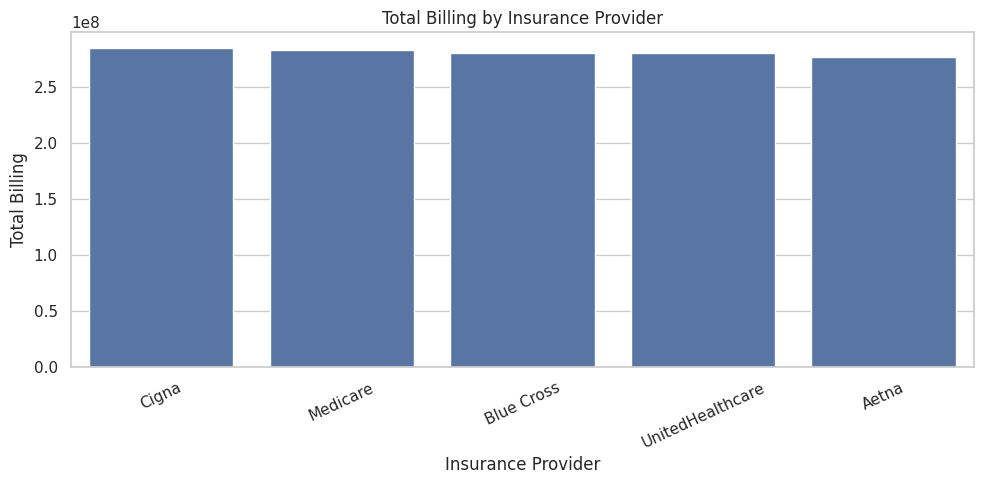

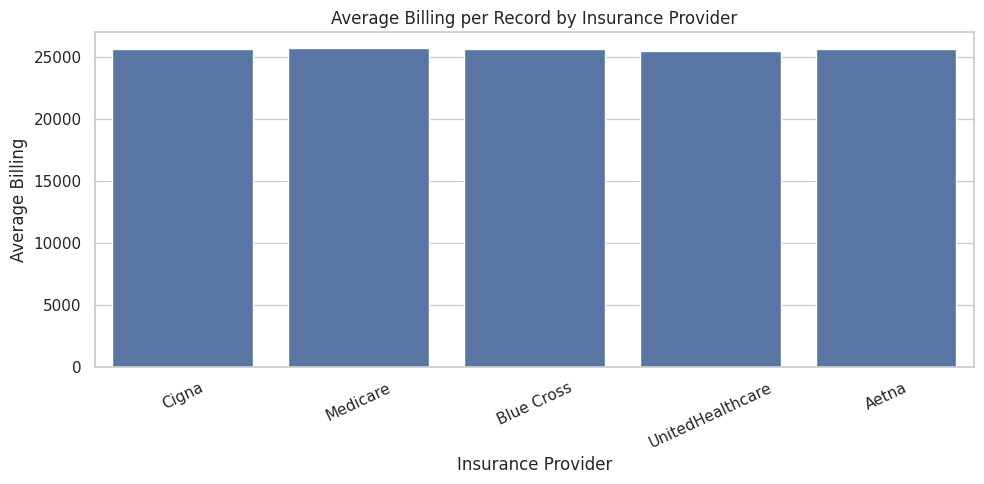

In [22]:

# Total billing by insurance provider

plt.figure(figsize=(10, 5))

sns.barplot(
    data=insurance_costs,
    x="Insurance Provider",
    y="Total_Billing"
)

plt.title("Total Billing by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Total Billing")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Average billing per record by insurance provider

plt.figure(figsize=(10, 5))

sns.barplot(
    data=insurance_costs,
    x="Insurance Provider",
    y="Average_Billing"
)

plt.title("Average Billing per Record by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Average Billing")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


In [23]:

# Calculate the correlation between length of stay and billing

pearson_corr = df_analysis[
    ["Length of Stay", "Billing Amount"]
].corr(method="pearson").iloc[0, 1]

spearman_corr = df_analysis[
    ["Length of Stay", "Billing Amount"]
].corr(method="spearman").iloc[0, 1]

print("Pearson correlation:", round(pearson_corr, 4))
print("Spearman correlation:", round(spearman_corr, 4))


Pearson correlation: -0.0048
Spearman correlation: -0.0047


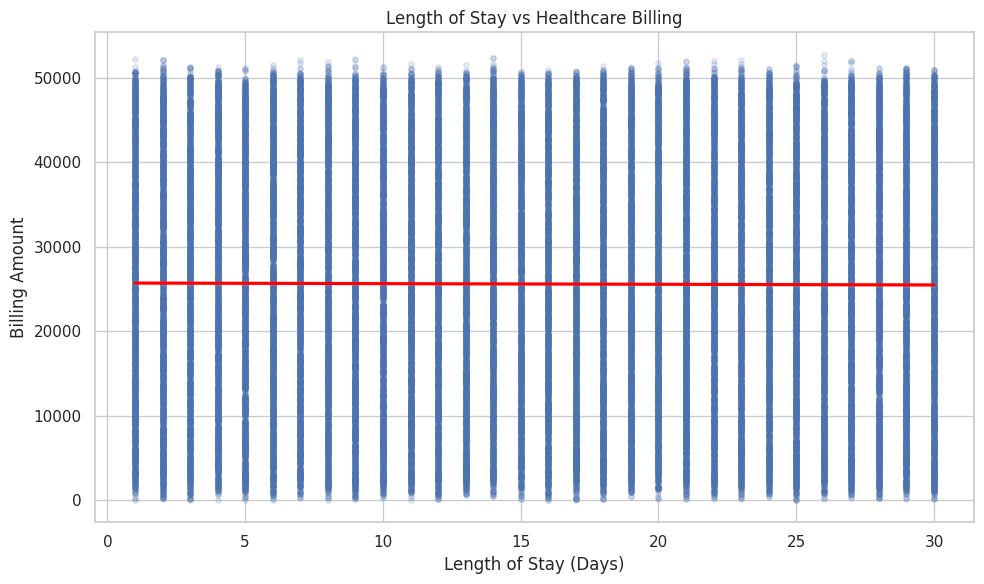

In [24]:

# Scatter plot with a fitted trend line

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_analysis,
    x="Length of Stay",
    y="Billing Amount",
    scatter_kws={"alpha": 0.15, "s": 15},
    line_kws={"color": "red"}
)

plt.title("Length of Stay vs Healthcare Billing")
plt.xlabel("Length of Stay (Days)")
plt.ylabel("Billing Amount")
plt.tight_layout()
plt.show()


In [25]:

# Determine how many distinct hospitals exist
unique_hospitals = df_analysis["Hospital"].nunique()

print("Unique hospital names:", unique_hospitals)
print("Total records:", len(df_analysis))

print(
    "Records per hospital summary:"
)
display(
    df_analysis.groupby("Hospital")
    .size()
    .describe()
)

# Check how many hospitals have very few records
hospital_counts = df_analysis["Hospital"].value_counts()

print(
    "\nHospitals with 1 record:",
    (hospital_counts == 1).sum()
)

print(
    "Hospitals with 5 or fewer records:",
    (hospital_counts <= 5).sum()
)

print(
    "Hospitals with 20 or more records:",
    (hospital_counts >= 20).sum()
)


Unique hospital names: 39814
Total records: 54858
Records per hospital summary:


,0
count,39814.000000
mean,1.377857
std,1.389248
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,44.000000



Hospitals with 1 record: 32025
Hospitals with 5 or fewer records: 39270
Hospitals with 20 or more records: 37


,Medical Condition,Patient_Count,Total_Billing,Average_Billing,Median_Billing
5,Obesity,9127,2.360171e+08,25859.22,26200.51
3,Diabetes,9197,2.364947e+08,25714.33,25681.01
1,Asthma,9077,2.331462e+08,25685.39,25684.41
4,Hypertension,9130,2.333473e+08,25558.31,25337.54
0,Arthritis,9206,2.351650e+08,25544.75,25629.71
2,Cancer,9121,2.299032e+08,25205.92,24990.11


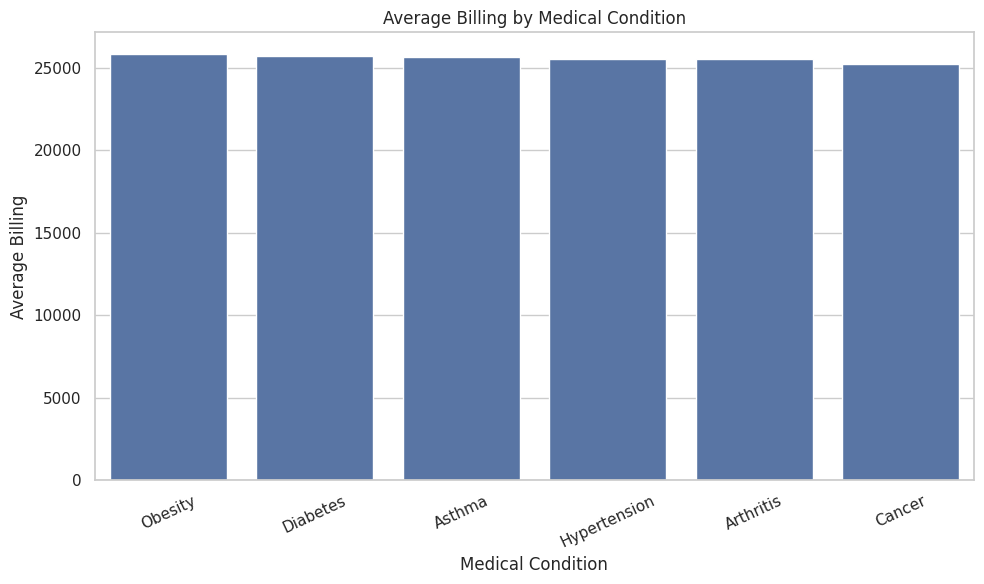

In [26]:

# Compare billing across medical conditions

condition_costs = (
    df_analysis.groupby("Medical Condition")
    .agg(
        Patient_Count=("Billing Amount", "size"),
        Total_Billing=("Billing Amount", "sum"),
        Average_Billing=("Billing Amount", "mean"),
        Median_Billing=("Billing Amount", "median")
    )
    .reset_index()
    .sort_values("Average_Billing", ascending=False)
)

display(condition_costs.round(2))

# Compare average billing across conditions
plt.figure(figsize=(10, 6))

sns.barplot(
    data=condition_costs,
    x="Medical Condition",
    y="Average_Billing"
)

plt.title("Average Billing by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Average Billing")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


,Admission Type,Patient_Count,Total_Billing,Average_Billing,Median_Billing
0,Elective,18436,4.731466e+08,25664.28,25708.16
2,Urgent,18352,4.692180e+08,25567.67,25595.08
1,Emergency,18070,4.617090e+08,25551.13,25465.12


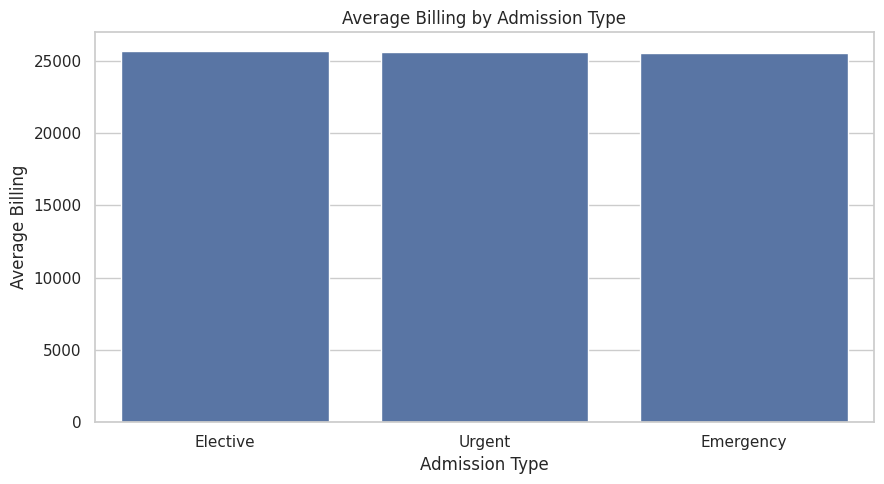

In [27]:

# Examine billing across admission types

admission_costs = (
    df_analysis.groupby("Admission Type")
    .agg(
        Patient_Count=("Billing Amount", "size"),
        Total_Billing=("Billing Amount", "sum"),
        Average_Billing=("Billing Amount", "mean"),
        Median_Billing=("Billing Amount", "median")
    )
    .reset_index()
    .sort_values("Average_Billing", ascending=False)
)

display(admission_costs.round(2))

# Visualize average billing by admission type
plt.figure(figsize=(9, 5))

sns.barplot(
    data=admission_costs,
    x="Admission Type",
    y="Average_Billing"
)

plt.title("Average Billing by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Average Billing")
plt.tight_layout()
plt.show()


,Medication,Patient_Count,Total_Billing,Average_Billing,Median_Billing
1,Ibuprofen,11002,2.837970e+08,25795.04,25871.70
0,Aspirin,10963,2.811694e+08,25647.12,25528.83
3,Paracetamol,10944,2.802372e+08,25606.47,25907.53
4,Penicillin,10931,2.791766e+08,25539.89,25273.43
2,Lipitor,11018,2.796934e+08,25385.13,25422.08


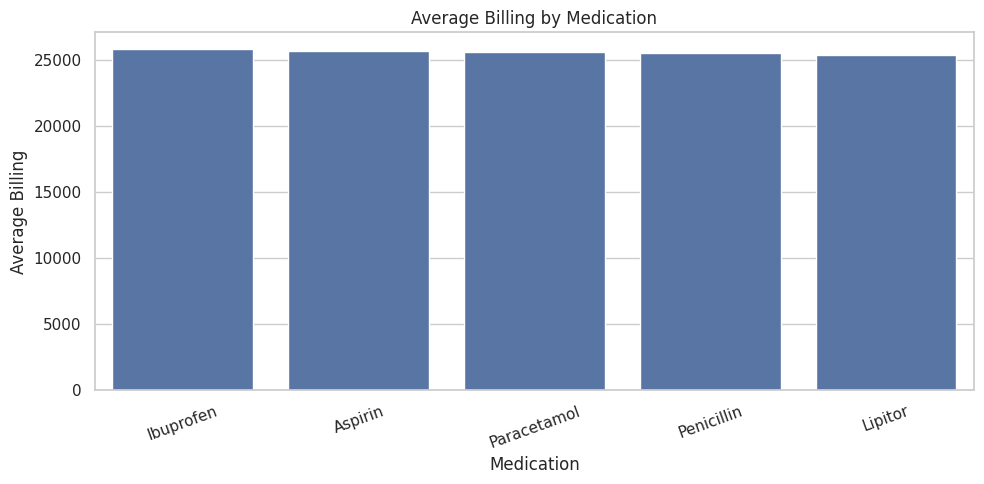

In [28]:

# Examine billing across medication categories

medication_costs = (
    df_analysis.groupby("Medication")
    .agg(
        Patient_Count=("Billing Amount", "size"),
        Total_Billing=("Billing Amount", "sum"),
        Average_Billing=("Billing Amount", "mean"),
        Median_Billing=("Billing Amount", "median")
    )
    .reset_index()
    .sort_values("Average_Billing", ascending=False)
)

display(medication_costs.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=medication_costs,
    x="Medication",
    y="Average_Billing"
)

plt.title("Average Billing by Medication")
plt.xlabel("Medication")
plt.ylabel("Average Billing")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [29]:

# Total billing can be decomposed into:
# number of records multiplied by average billing per record

overall_volume = len(df_analysis)

overall_average_bill = df_analysis[
    "Billing Amount"
].mean()

reconstructed_total = (
    overall_volume * overall_average_bill
)

print("Number of records:", overall_volume)
print("Average billing:", round(overall_average_bill, 2))
print("Reconstructed total billing:", round(
    reconstructed_total, 2
))
print("Actual total billing:", round(
    df_analysis["Billing Amount"].sum(), 2
))


Number of records: 54858
Average billing: 25594.69
Reconstructed total billing: 1404073534.71
Actual total billing: 1404073534.71


In [30]:

# Compare the spread of average billing across categories

category_summaries = {
    "Medical Condition": condition_costs,
    "Admission Type": admission_costs,
    "Medication": medication_costs,
    "Insurance Provider": insurance_costs
}

range_results = []

for category, table in category_summaries.items():
    min_avg = table["Average_Billing"].min()
    max_avg = table["Average_Billing"].max()

    range_results.append({
        "Category": category,
        "Lowest Average Bill": min_avg,
        "Highest Average Bill": max_avg,
        "Difference": max_avg - min_avg,
        "Difference (% of overall mean)": (
            (max_avg - min_avg) /
            df_analysis["Billing Amount"].mean()
        ) * 100
    })

range_df = pd.DataFrame(range_results)

display(range_df.round(2))


,Category,Lowest Average Bill,Highest Average Bill,Difference,Difference (% of overall mean)
0,Medical Condition,25205.92,25859.22,653.29,2.55
1,Admission Type,25551.13,25664.28,113.14,0.44
2,Medication,25385.13,25795.04,409.91,1.60
3,Insurance Provider,25457.61,25678.09,220.48,0.86


,Length of Stay,Patient_Count,Average_Billing,Median_Billing,Billing_Std
0,1,1807,25346.31,25194.85,14019.56
1,2,1824,25338.80,25462.88,14509.33
2,3,1823,25988.67,26692.21,13895.38
3,4,1844,26060.52,26351.01,14352.41
4,5,1817,25500.75,25636.79,14045.92
5,6,1887,25947.92,26065.70,14370.24
6,7,1859,25844.49,25682.15,14156.00
7,8,1803,26153.07,26160.92,14140.37
8,9,1853,25612.55,25503.89,14105.83
9,10,1783,25513.26,26200.61,14381.62


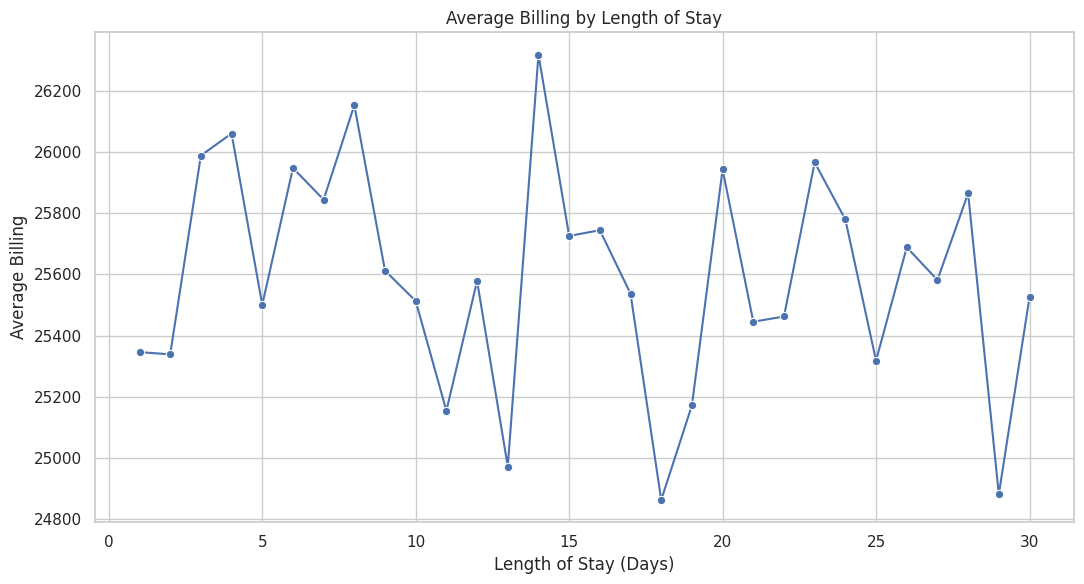

In [31]:

# Examine average and standard deviation of billing
# for each length of stay

stay_billing = (
    df_analysis.groupby("Length of Stay")
    .agg(
        Patient_Count=("Billing Amount", "size"),
        Average_Billing=("Billing Amount", "mean"),
        Median_Billing=("Billing Amount", "median"),
        Billing_Std=("Billing Amount", "std")
    )
    .reset_index()
)

display(stay_billing.round(2))

# Plot average billing for each length of stay
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=stay_billing,
    x="Length of Stay",
    y="Average_Billing",
    marker="o"
)

plt.title("Average Billing by Length of Stay")
plt.xlabel("Length of Stay (Days)")
plt.ylabel("Average Billing")
plt.tight_layout()
plt.show()


In [32]:

# Examine the number of distinct billing values
print(
    "Unique billing values:",
    df_analysis["Billing Amount"].nunique()
)

print(
    "Total billing records:",
    len(df_analysis)
)

# Compare quantiles
print("\nBilling quantiles:")
display(
    df_analysis["Billing Amount"]
    .quantile([0, 0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99, 1])
    .to_frame(name="Billing Amount")
)

# Check whether billing values are concentrated
# in a narrow or broad range
print(
    "\nCoefficient of variation:",
    round(
        df_analysis["Billing Amount"].std() /
        df_analysis["Billing Amount"].mean(),
        4
    )
)


Unique billing values: 49903
Total billing records: 54858

Billing quantiles:


,Billing Amount
0.00,9.238787
0.01,1419.468001
0.10,5961.494973
0.25,13299.929625
0.50,25593.872995
0.75,37846.108562
0.90,45168.079312
0.99,49855.035527
1.00,52764.276740



Coefficient of variation: 0.5539


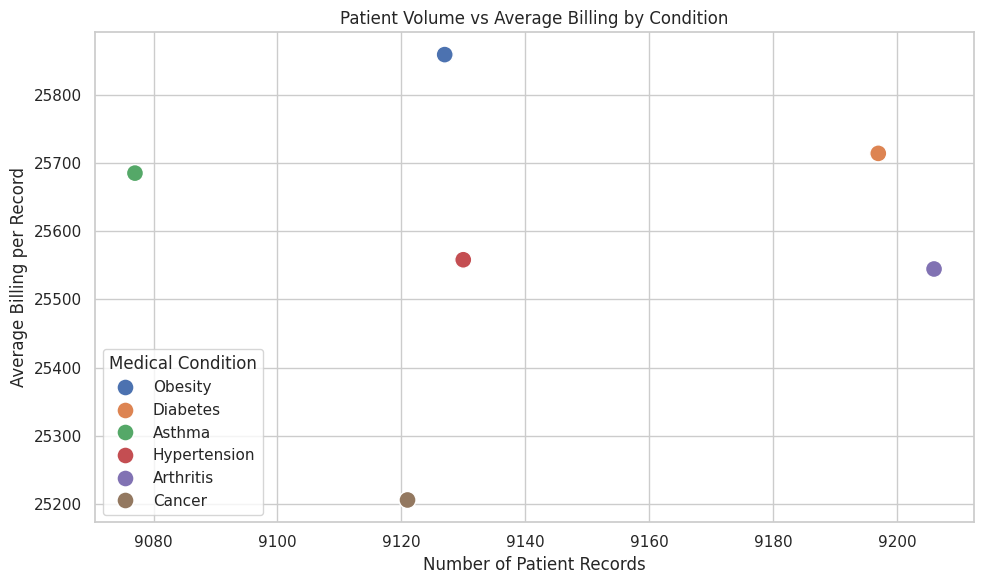

In [33]:

# Compare patient volume and average billing
# across the medical conditions

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=condition_costs,
    x="Patient_Count",
    y="Average_Billing",
    hue="Medical Condition",
    s=150
)

plt.title("Patient Volume vs Average Billing by Condition")
plt.xlabel("Number of Patient Records")
plt.ylabel("Average Billing per Record")
plt.tight_layout()
plt.show()


In [34]:

from scipy.stats import f_oneway

# Split billing amounts into groups by medical condition
billing_groups = [
    group["Billing Amount"].values
    for _, group in df_analysis.groupby("Medical Condition")
]

# Test whether all group means are equal
f_statistic, p_value = f_oneway(*billing_groups)

print("ANOVA F-statistic:", round(f_statistic, 4))
print("ANOVA p-value:", p_value)

if p_value < 0.05:
    print(
        "Statistical conclusion: At least one condition's "
        "mean billing differs from another."
    )
else:
    print(
        "Statistical conclusion: Insufficient evidence of "
        "a difference in mean billing."
    )


ANOVA F-statistic: 2.2481
ANOVA p-value: 0.04683306734200308
Statistical conclusion: At least one condition's mean billing differs from another.


In [35]:

# Summarize the major results for the technical documentation

overall_mean = df_analysis["Billing Amount"].mean()
overall_total = df_analysis["Billing Amount"].sum()

findings_summary = pd.DataFrame([
    {
        "Analysis": "Total recorded billing",
        "Result": f"{overall_total:,.2f}",
        "Interpretation": "Total billing in the cleaned analysis dataset"
    },
    {
        "Analysis": "Average billing per record",
        "Result": f"{overall_mean:,.2f}",
        "Interpretation": "Mean recorded billing per patient record"
    },
    {
        "Analysis": "Average length of stay",
        "Result": f"{df_analysis['Length of Stay'].mean():.2f} days",
        "Interpretation": "Mean calendar-day difference between admission and discharge"
    },
    {
        "Analysis": "Length of stay vs billing",
        "Result": f"Pearson r = {pearson_corr:.4f}",
        "Interpretation": "Practically no linear association"
    },
    {
        "Analysis": "Unique hospital names",
        "Result": f"{df_analysis['Hospital'].nunique():,}",
        "Interpretation": "Hospital-level comparisons are limited by fragmented names"
    }
])

display(findings_summary)


,Analysis,Result,Interpretation
0,Total recorded billing,"1,404,073,534.71",Total billing in the cleaned analysis dataset
1,Average billing per record,"25,594.69",Mean recorded billing per patient record
2,Average length of stay,15.50 days,Mean calendar-day difference between admission...
3,Length of stay vs billing,Pearson r = -0.0048,Practically no linear association
4,Unique hospital names,"39,814",Hospital-level comparisons are limited by frag...


# Conclusion

### Answer to the Business Question: What Drives Healthcare Costs?

Total healthcare billing is determined by both the number of patient records and the average billing amount per record. The analysis compared these metrics across insurance providers, medical conditions, admission types, medications, and hospitals.

The results show that average billing differences across insurance providers, medical conditions, admission types, and medications are relatively small. Patient counts across the main categories are also broadly similar, and total billing across insurance providers is relatively comparable. Therefore, the analysis does not indicate a strong difference in expenditure driven solely by higher average billing across these categories.

However, hospital-level comparisons are limited by the unusually large number of distinct hospital names and the small number of records associated with many of them. Consequently, the available evidence is insufficient to conclude definitively whether high total expenditure is primarily driven by patient volume or average billing at the hospital level.

A more reliable assessment would require standardized hospital identifiers and comparisons of patient volume, average billing, and total billing across hospitals with sufficient records.